# Retrieval-головы Qwen3-8B на усложнённом контексте

Графики по прогонам `results/new/qwen3_hard_fast`: задача `hard_niah`, данные и уровни — `data/needles_hard/README.md`. Головы найдены на простой задаче (`results/new/qwen3_detect`, рейтинг `copy_count`) и здесь не переопределяются.

Ноутбук читает только готовые результаты (`samples.jsonl`, `heads/*.npz`, `spool/run.json`), модель не нужна.

**Что посчитано.** Три оси, по четыре прогона на одних и тех же промптах:

| Ось | Уровни | Что меняется |
|---|---|---|
| A — вопрос | A0 дословный; A1 перефраз, ключ сохранён; A2 ключ заменён описанием; A3 и то и другое | формулировка вопроса |
| B — близнецы | B1 один близнец далеко; B2 три случайно; B3 три рядом; B4 запись с тем же ключом о другом | похожие записи с другим ответом |
| N — шум | N1 метеорит далеко; N2 рядом; N3 три ярких факта рядом; N4 метеорит под тем же городом | яркий посторонний факт |

| Прогон | Что |
|---|---|
| `none` | без маски, внимание сохранено |
| `top40`, `top60` | отключены 40 и 60 лучших голов детекции (`copy_count`) |
| `random60` | 60 случайных голов вне 100 лучших — контроль |

Сетка: 3 семейства (`lisbon`, `cairo`, `oslo`) × 11 длин (1000–30000) × 6 глубин (0–100) = 198 примеров на уровень. **A0 — общая точка отсчёта** для всех осей: игла без вставок и дословный вопрос.

**Как оценивается ответ.** По README, ROUGE на этих задачах использовать нельзя: ответ, списанный с близнеца, получает ROUGE-1 recall 54–85. Поэтому главный критерий — класс ответа по фактам:

| Класс | Условие |
|---|---|
| верно | все факты ответа, ничего из конкурирующих вставок |
| смешано | все факты ответа, но есть и факты близнецов или шума |
| частично | часть фактов ответа, без фактов вставок |
| путаница | не все факты ответа, есть факты близнеца или приманки |
| шум | не все факты ответа, есть факты шума |
| иное | ни одного из этих фактов |

| Раздел | Что показывает | Гипотеза плана |
|---|---|---|
| 1 | качество без маски: классы ответов по уровням, ROUGE против класса, карты «длина × глубина» | — |
| 2 | маска: доля верных при top40, top60, random60; чистый эффект маски с ДИ; во что превращаются ответы | H4 |
| 3 | куда смотрят 20 лучших голов: на иглу или на вставки; верные ответы против путаницы | H2 |
| 4 | остаются ли лучшие головы лучшими на каждом уровне | H1, H3 |
| 5 | примеры ответов | — |

## 0. Настройки

In [1]:
import os, re, sys, unicodedata
sys.path.insert(0, os.path.abspath(".."))   # корень репозитория: ноутбук лежит в vizual/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vizual import data, plots, style

RUNS_DIR = "results/new/qwen3_hard_fast"     # <ось>/<прогон>
AXES = ["A", "B", "N"]
RUNS = ["none", "top40", "top60", "random60"]
RANKING = "results/new/qwen3_detect/head_score_copy_count.json"            # по нему выбирались маскируемые головы
MASS_RANKING = "data/head_scores/head_scores_needle_attention_mass_v1_2.json"   # рейтинг по массе внимания (c0), для раздела 4

LAYERS, N_HEADS = list(range(36)), 32
TOP = 20                  # сколько лучших голов детекции смотреть в разделах 3 и 4
BOOT = 2000               # повторов бутстрепа для доверительных интервалов
SEED = 0
SAVE = False              # сохранять рисунки в vizual/figures/

style.use(scale=1.0, dpi=110)
T = style.THEME

def show(ax, name):
    if SAVE:
        plots.save(np.ravel(ax)[0].figure, name)
    plt.show()


CLASSES = ["correct", "mixed", "partial", "confusion", "noise", "other"]
CLASS_LABELS = {"correct": "верно", "mixed": "смешано", "partial": "частично", "confusion": "путаница", "noise": "шум", "other": "иное"}
CLASS_COLORS = {"correct": T.colors["top"], "mixed": "#9cc3ee", "partial": "#f2c46b", "confusion": T.colors["random"],
                "noise": "#7a4fd6", "other": T.colors["muted"]}
RUN_LABELS = {"none": "без маски", "top40": "40 лучших", "top60": "60 лучших", "random60": "60 случайных"}
RUN_COLORS = {"none": T.colors["none"], "top40": "#86b4ea", "top60": T.colors["top"], "random60": T.colors["random"]}
plots.VALUE_LABELS["correct"] = "верных ответов, %"


def plain(text):
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", unicodedata.normalize("NFKC", text).lower())).strip()


def has_fact(text, fact):
    """Одно из написаний факта стоит в тексте целыми словами (как has_fact в rh/metrics.py)."""
    text = f" {plain(text)} "
    return any(f" {plain(spelling)} " in text for spelling in fact)


def facts(value):
    """Список фактов из строки samples.jsonl; у примеров без вставок поля может не быть (NaN)."""
    return value if isinstance(value, list) else []


def fact_class(row):
    """Класс ответа по фактам — то же правило, что fact_class в rh/metrics.py (README, раздел 5)."""
    found = sum(has_fact(row["response"], f) for f in row["answer_key"])
    confused = any(has_fact(row["response"], f) for f in facts(row.get("confusion_facts")))
    noisy = any(has_fact(row["response"], f) for f in facts(row.get("noise_facts")))
    if found == len(row["answer_key"]):
        name = "mixed" if confused or noisy else "correct"
    else:
        name = "confusion" if confused else "noise" if noisy else "partial" if found else "other"
    return pd.Series({"answer_class": name, "facts_found": found / len(row["answer_key"])})


def level_order(levels):
    """A0, A1, …, B1, …, N4: по оси, затем по номеру."""
    return sorted(set(levels), key=lambda s: (s[0], int(re.sub(r"\D", "", s) or 0), s))


def bootstrap(values, n=BOOT, seed=SEED):
    """Среднее и 95% интервал бутстрепа по примерам, в процентах."""
    v = np.asarray(values, dtype=float)
    if len(v) == 0:
        return np.nan, np.nan, np.nan
    boots = np.random.default_rng(seed).choice(v, (n, len(v))).mean(1)
    return 100 * v.mean(), 100 * np.percentile(boots, 2.5), 100 * np.percentile(boots, 97.5)

### Загрузка

Таблица `hard`: строка — пример одного прогона. Столбцы `axis`, `run`, `family`, `level`, ответ, ROUGE, точная фраза, класс ответа `answer_class` и доля найденных фактов `facts_found`.

In [2]:
parts = []
for axis in AXES:
    for run in RUNS:
        out = f"{RUNS_DIR}/{axis}/{run}"
        if not os.path.exists(os.path.join(data.path(out), "samples.jsonl")):
            print("нет прогона:", out)
            continue
        parts.append(data.load_run(out, name=run).assign(axis=axis))
hard = pd.concat(parts, ignore_index=True)
hard[["answer_class", "facts_found"]] = hard.apply(fact_class, axis=1)
hard["correct"] = hard["answer_class"] == "correct"

LEVELS = {axis: level_order(hard.loc[hard["axis"] == axis, "level"]) for axis in AXES}
FAMILIES = sorted(hard["family"].unique())
base = hard[(hard["axis"] == "A") & (hard["level"] == "A0")]   # точка отсчёта для осей B и N

print(f"примеров: {len(hard)}; семейства: {FAMILIES}")
hard.groupby(["axis", "run"]).size().unstack()[RUNS]

примеров: 9504; семейства: ['cairo', 'lisbon', 'oslo']


run,none,top40,top60,random60
axis,,,,
A,792,792,792,792
B,792,792,792,792
N,792,792,792,792


## 1. Качество без маски

Сначала проверка базы: на A0 модель должна отвечать верно почти всегда, иначе дальше сравнивать нечего. Затем — как падает доля верных и во что превращаются остальные ответы на каждом уровне.

In [3]:
def class_table(df, by):
    share = df.groupby(by)["answer_class"].value_counts(normalize=True).unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0) * 100
    extra = df.groupby(by).agg(примеров=("id", "size"), ROUGE1_больше_50=("success", "mean"), точная_фраза=("exact", "mean"))
    extra[["ROUGE1_больше_50", "точная_фраза"]] *= 100
    return extra.join(share.rename(columns=CLASS_LABELS)).round(1)

none = hard[hard["run"] == "none"]
table = class_table(none, ["axis", "level"])
table.loc[[(a, l) for a in AXES for l in LEVELS[a]]]

примеров  ROUGE1_больше_50  точная_фраза  верно  смешано  \
axis level                                                             
A    A0          198             100.0         100.0  100.0        0   
     A1          198             100.0          64.6  100.0        0   
     A2          198             100.0         100.0  100.0        0   
     A3          198              87.9          54.5   87.4        0   
B    B1          198             100.0         100.0  100.0        0   
     B2          198              99.5          99.5   99.5        0   
     B3          198             100.0          99.5   99.5        0   
     B4          198             100.0         100.0  100.0        0   
N    N1          198             100.0         100.0  100.0        0   
     N2          198             100.0         100.0  100.0        0   
     N3          198             100.0         100.0  100.0        0   
     N4          198             100.0         100.0  100.0        0   

            частично  путаница  шум  иное  
axis level                                 
A    A0            0       0.0    0   0.0  
     A1            0       0.0    0   0.0  
     A2            0       0.0    0   0.0  
     A3            0       0.0    0  12.6  
B    B1            0       0.0    0   0.0  
     B2            0       0.5    0   0.0  
     B3            0       0.5    0   0.0  
     B4            0       0.0    0   0.0  
N    N1            0       0.0    0   0.0  
     N2            0       0.0    0   0.0  
     N3            0       0.0    0   0.0  
     N4            0       0.0    0   0.0

### 1.1. Классы ответов по уровням

Столбец — уровень, высота частей — доли классов. Для осей B и N слева добавлен A0 как точка отсчёта.

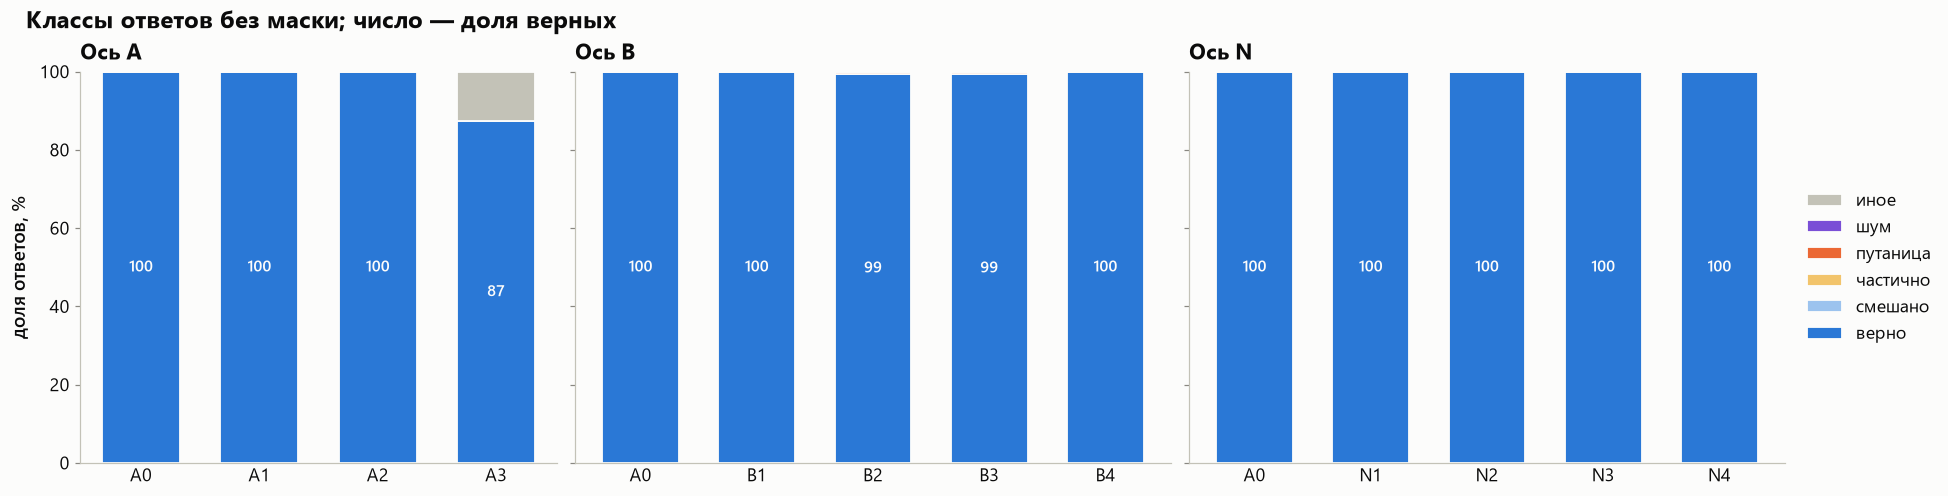

In [4]:
def class_bars(df, by, order, labels=None, ax=None, legend=True, title=None, subtitle=None):
    """Доли классов ответа столбиками, по значениям столбца by в порядке order."""
    ax = plots.new_ax(ax, 0.85 * len(order) + 3.2, 4.2)
    share = (df.groupby(by)["answer_class"].value_counts(normalize=True).unstack(fill_value=0) * 100).reindex(index=order, columns=CLASSES, fill_value=0)
    xs, bottom = np.arange(len(order)), np.zeros(len(order))
    for c in CLASSES:
        ax.bar(xs, share[c], bottom=bottom, width=0.66, color=CLASS_COLORS[c], edgecolor=T.surface, linewidth=1.2, label=CLASS_LABELS[c])
        bottom += share[c].to_numpy()
    for x, v in zip(xs, share["correct"]):
        if v >= 8:
            ax.annotate(f"{v:.0f}", (x, v / 2), ha="center", va="center", color=T.surface, fontsize=T.font - 1, fontweight="semibold")
    ax.set_xticks(xs, labels or order)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", visible=False)
    ax.set_ylim(0, 100)
    plots.round_axis(ax, "y", 0, 100, 20)
    ax.set_ylabel("доля ответов, %")
    if legend:
        ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), reverse=True)
    plots.titles(ax, title, subtitle)
    return ax

fig, axes = plt.subplots(1, len(AXES), figsize=style.size(5.2 * len(AXES) + 2, 4.4), sharey=True,
                         gridspec_kw={"width_ratios": [len(LEVELS[a]) + (a != "A") for a in AXES]})
for ax, axis in zip(axes, AXES):
    part = none[none["axis"] == axis]
    order = LEVELS[axis] if axis == "A" else ["A0"] + LEVELS[axis]
    if axis != "A":
        part = pd.concat([base[base["run"] == "none"], part])
    class_bars(part, "level", order, ax=ax, legend=ax is axes[-1], title=f"Ось {axis}")
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.suptitle("Классы ответов без маски; число — доля верных", x=0.01, ha="left", fontweight="bold")
show(axes, "hard_classes")

#### По семействам

Шаблоны семейств разной сложности (README, раздел 8), поэтому эффект уровня проверяется внутри семейства: совпадает ли направление у всех трёх.

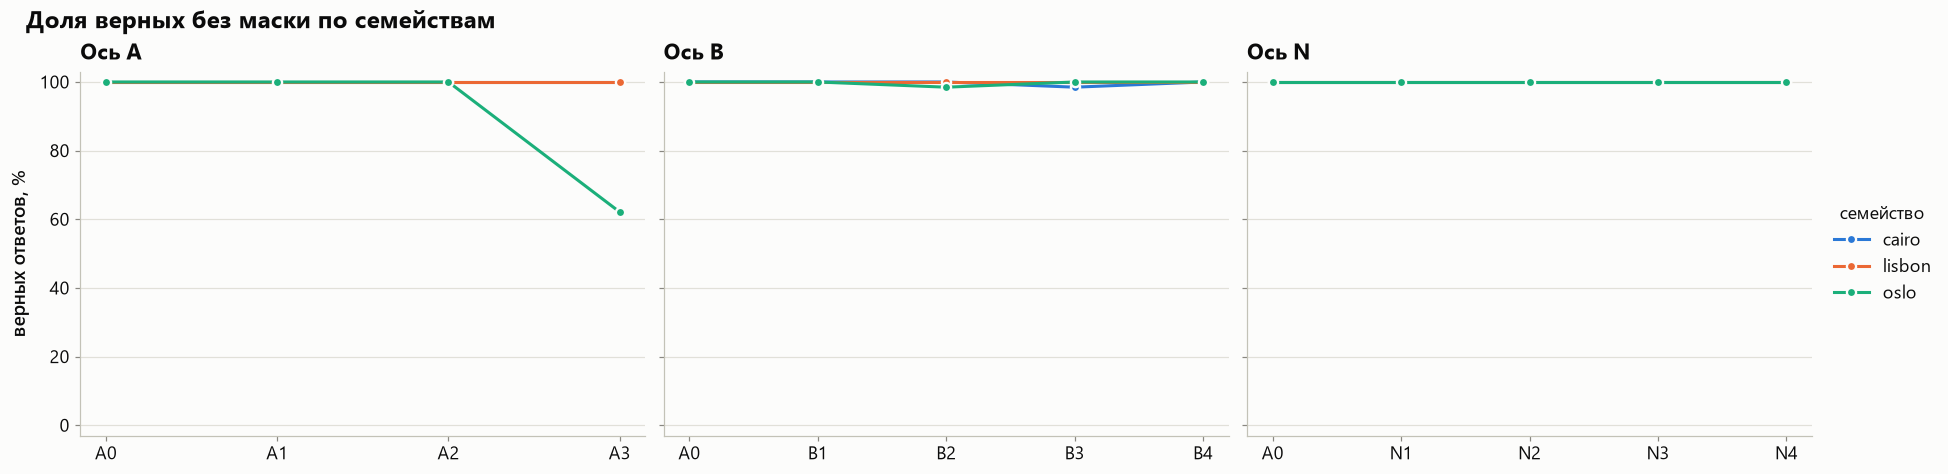

In [5]:
fig, axes = plt.subplots(1, len(AXES), figsize=style.size(5.2 * len(AXES) + 2, 4.2), sharey=True)
for ax, axis in zip(axes, AXES):
    order = LEVELS[axis] if axis == "A" else ["A0"] + LEVELS[axis]
    part = none[none["axis"] == axis]
    if axis != "A":
        part = pd.concat([base[base["run"] == "none"], part])
    for family, color in zip(FAMILIES, (T.colors["top"], T.colors["random"], T.colors["random_groups"])):
        line = part[part["family"] == family].groupby("level")["correct"].mean().reindex(order) * 100
        ax.plot(range(len(order)), line.to_numpy(), marker="o", color=color, label=family)
    ax.set_xticks(range(len(order)), order)
    ax.set_ylim(-3, 103)
    plots.round_axis(ax, "y", 0, 100, 20)
    plots.titles(ax, f"Ось {axis}")
axes[0].set_ylabel("верных ответов, %")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="семейство")
fig.suptitle("Доля верных без маски по семействам", x=0.01, ha="left", fontweight="bold")
show(axes, "hard_families")

### 1.2. Почему не ROUGE

Для каждого уровня три доли: ответы с ROUGE-1 recall > 50 (критерий статьи), с точной фразой эталона и класс «верно». Там, где первый столбик заметно выше третьего, ROUGE засчитывает как успех ответы, списанные с близнеца или неполные.

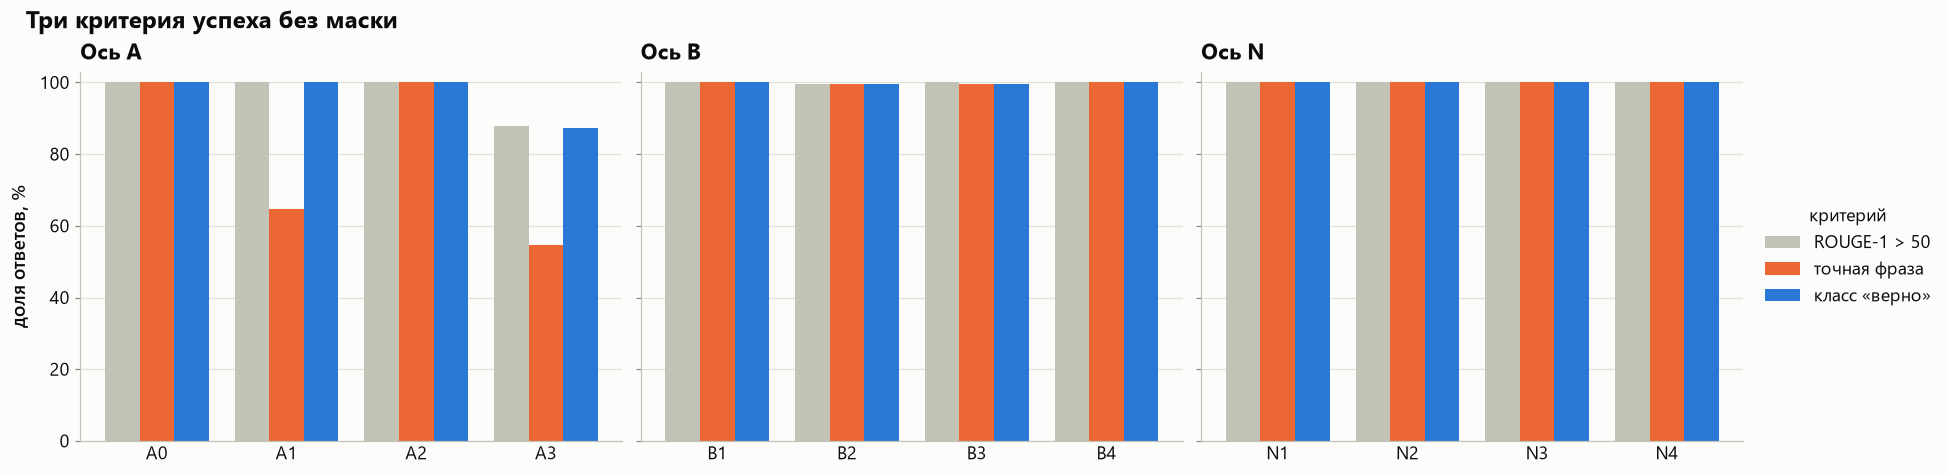

In [6]:
CRITERIA = {"success": "ROUGE-1 > 50", "exact": "точная фраза", "correct": "класс «верно»"}
CRIT_COLORS = [T.colors["muted"], T.colors["random"], T.colors["top"]]

fig, axes = plt.subplots(1, len(AXES), figsize=style.size(5.2 * len(AXES) + 2, 4.2), sharey=True)
for ax, axis in zip(axes, AXES):
    order = LEVELS[axis]
    part = none[none["axis"] == axis]
    shares = part.groupby("level")[list(CRITERIA)].mean().reindex(order) * 100
    width = 0.8 / len(CRITERIA)
    for i, (column, color) in enumerate(zip(CRITERIA, CRIT_COLORS)):
        ax.bar(np.arange(len(order)) + (i - 1) * width, shares[column], width=width, color=color, label=CRITERIA[column])
    ax.set_xticks(range(len(order)), order)
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, 103)
    plots.round_axis(ax, "y", 0, 100, 20)
    plots.titles(ax, f"Ось {axis}")
axes[0].set_ylabel("доля ответов, %")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="критерий")
fig.suptitle("Три критерия успеха без маски", x=0.01, ha="left", fontweight="bold")
show(axes, "hard_criteria")

### 1.3. Карты «длина × глубина»

Доля верных ответов по длине контекста и глубине иглы, без маски; в клетке 3 примера (по одному на семейство). Число в заголовке панели — доля верных по уровню.

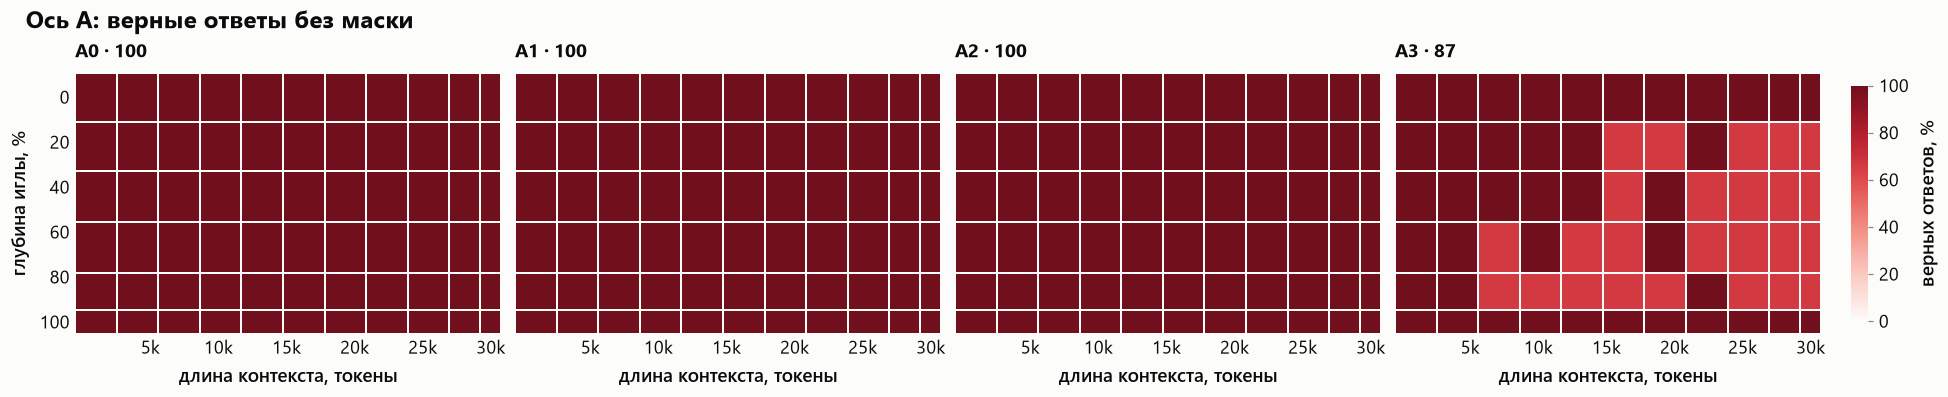

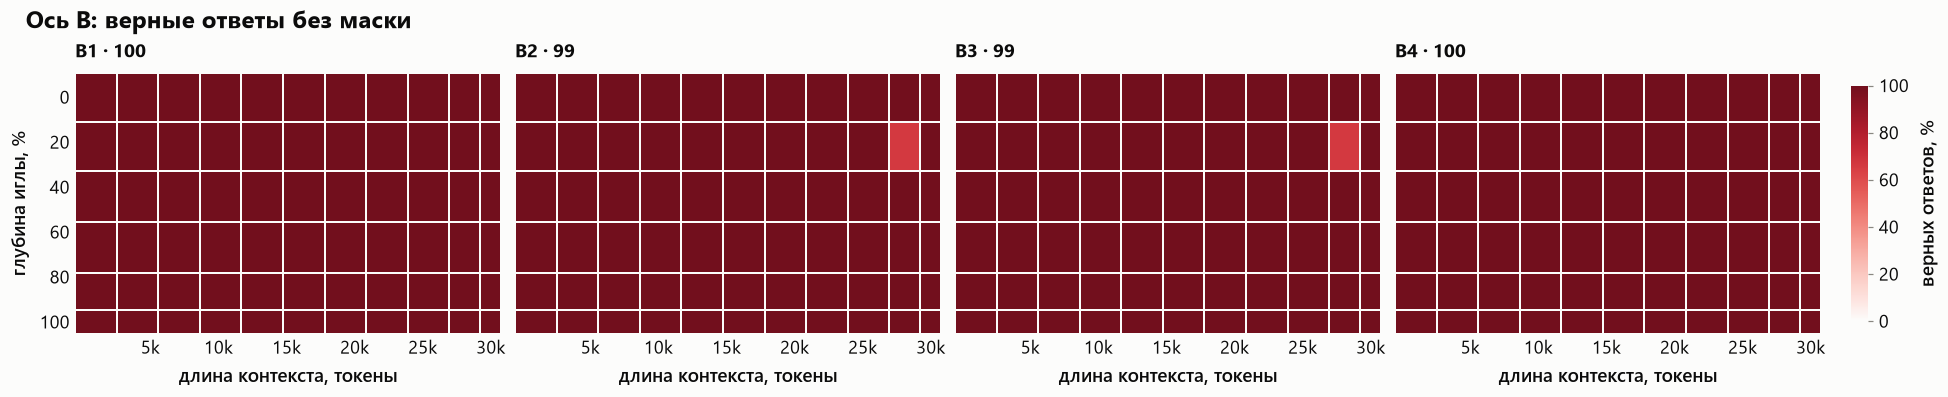

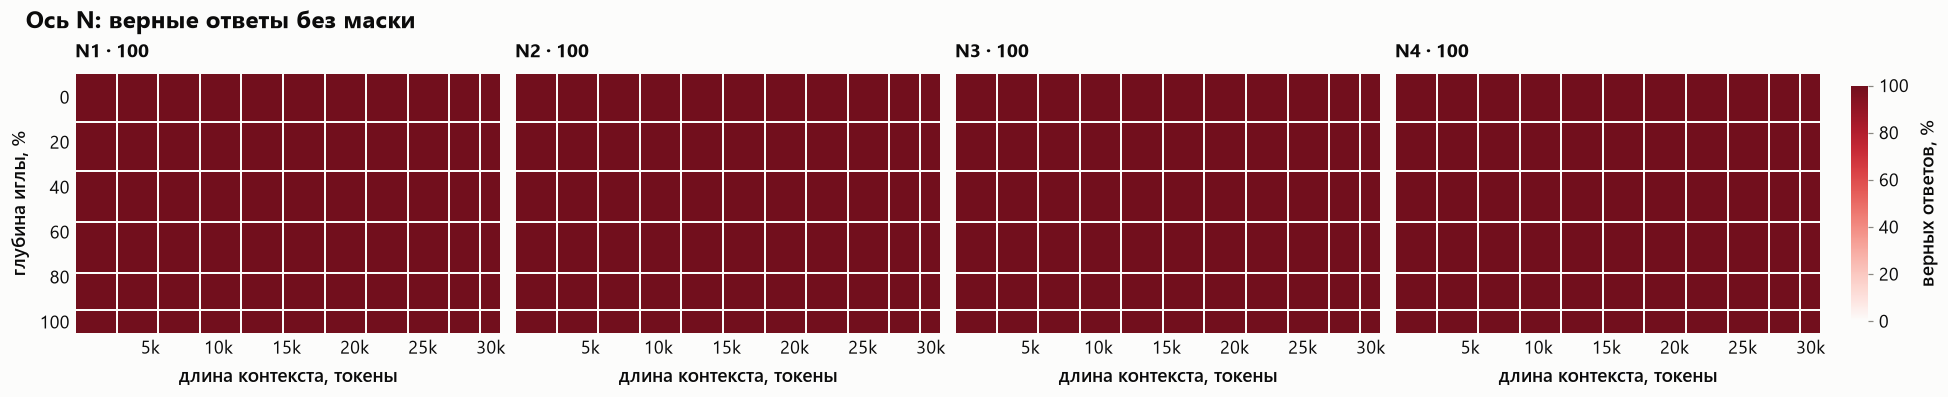

In [7]:
for axis in AXES:
    part = none[none["axis"] == axis]
    show(plots.niah_grid(part.assign(run=part["level"]), {lv: lv for lv in LEVELS[axis]}, value="correct", columns=4,
                         title=f"Ось {axis}: верные ответы без маски"), f"hard_niah_{axis}")

## 2. Маскирование

Те же промпты с отключёнными головами. Вопрос H4: зависит ли сложный уровень от голов простой задачи так же, как простой. Сравнение парное: у всех четырёх прогонов одни и те же примеры (`id`).

### 2.1. Доля верных по уровням и прогонам

Точка — доля верных, отрезок — 95% интервал бутстрепа по примерам уровня (198 примеров).

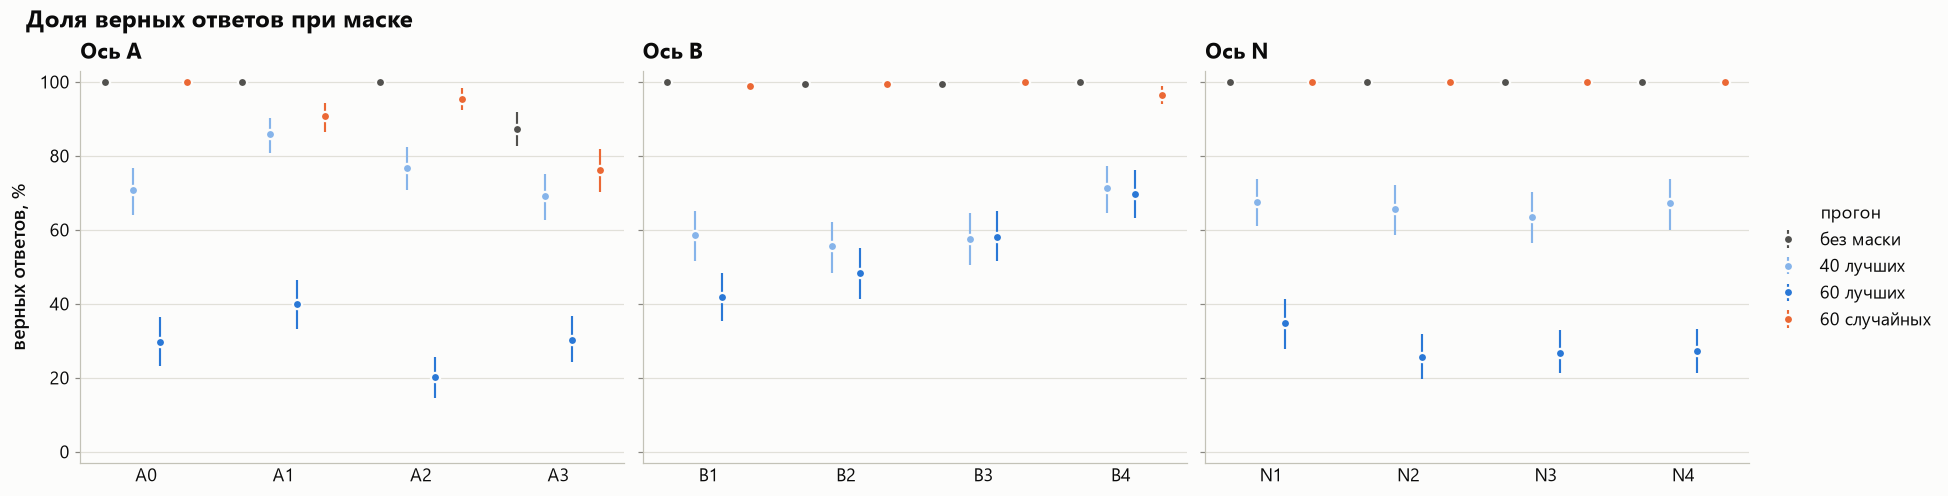

run         без маски  40 лучших  60 лучших  60 случайных
axis level                                               
A    A0         100.0       70.7       29.8         100.0
     A1         100.0       85.9       39.9          90.9
     A2         100.0       76.8       20.2          95.5
     A3          87.4       69.2       30.3          76.3
B    B1         100.0       58.6       41.9          99.0
     B2          99.5       55.6       48.5          99.5
     B3          99.5       57.6       58.1         100.0
     B4         100.0       71.2       69.7          96.5
N    N1         100.0       67.7       34.8         100.0
     N2         100.0       65.7       25.8         100.0
     N3         100.0       63.6       26.8         100.0
     N4         100.0       67.2       27.3         100.0

In [8]:
rows = []
for (axis, level, run), part in hard.groupby(["axis", "level", "run"]):
    mean, lo, hi = bootstrap(part["correct"])
    rows.append({"axis": axis, "level": level, "run": run, "correct": mean, "lo": lo, "hi": hi, "n": len(part)})
by_run = pd.DataFrame(rows)

fig, axes = plt.subplots(1, len(AXES), figsize=style.size(5.2 * len(AXES) + 2, 4.4), sharey=True)
for ax, axis in zip(axes, AXES):
    order = LEVELS[axis]
    width = 0.8 / len(RUNS)
    for i, run in enumerate(RUNS):
        part = by_run[(by_run["axis"] == axis) & (by_run["run"] == run)].set_index("level").reindex(order)
        xs = np.arange(len(order)) + (i - (len(RUNS) - 1) / 2) * width
        ax.errorbar(xs, part["correct"], yerr=[part["correct"] - part["lo"], part["hi"] - part["correct"]], fmt="o",
                    color=RUN_COLORS[run], ecolor=RUN_COLORS[run], elinewidth=1.4, capsize=0, label=RUN_LABELS[run])
    ax.set_xticks(range(len(order)), order)
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(-3, 103)
    plots.round_axis(ax, "y", 0, 100, 20)
    plots.titles(ax, f"Ось {axis}")
axes[0].set_ylabel("верных ответов, %")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="прогон")
fig.suptitle("Доля верных ответов при маске", x=0.01, ha="left", fontweight="bold")
show(axes, "hard_mask_correct")

by_run.pivot_table(index=["axis", "level"], columns="run", values="correct")[RUNS].round(1).rename(columns=RUN_LABELS)

### 2.2. Чистый эффект маски

`Δ_net = p_верно(60 случайных) − p_верно(60 лучших)` — насколько отключение лучших голов вредит сильнее, чем отключение стольких же случайных. Интервал — парный бутстреп по примерам. Рядом — `p_верно(без маски) − p_верно(60 лучших)`, полное падение.

Если на сложных уровнях `Δ_net` меньше, чем на A0, головы простой задачи важны для них слабее (H4 подтверждается).

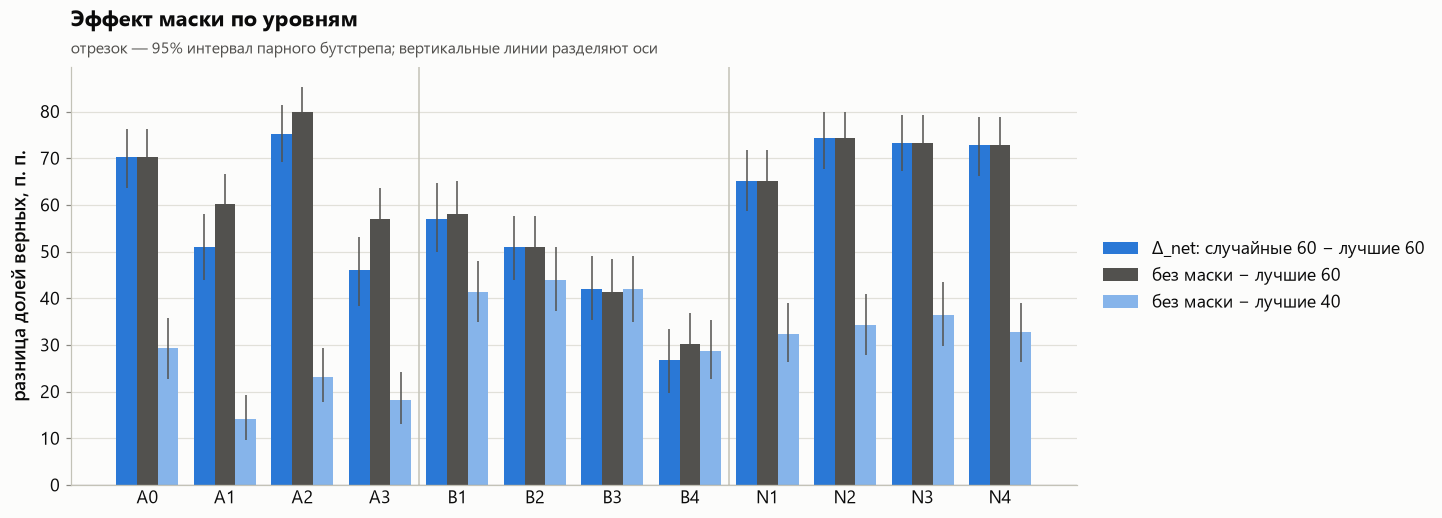

сравнение  Δ_net: случайные 60 − лучшие 60 без маски − лучшие 60  \
axis level                                                         
A    A0                  70.2 [63.6; 76.3]     70.2 [63.6; 76.3]   
     A1                  51.0 [43.9; 58.1]     60.1 [53.0; 66.7]   
     A2                  75.3 [69.2; 81.3]     79.8 [74.2; 85.4]   
     A3                  46.0 [38.4; 53.0]     57.1 [50.0; 63.6]   
B    B1                  57.1 [50.0; 64.6]     58.1 [51.0; 65.2]   
     B2                  51.0 [43.9; 57.6]     51.0 [43.9; 57.6]   
     B3                  41.9 [35.4; 49.0]     41.4 [34.8; 48.5]   
     B4                  26.8 [19.7; 33.3]     30.3 [23.7; 36.9]   
N    N1                  65.2 [58.6; 71.7]     65.2 [58.6; 71.7]   
     N2                  74.2 [67.7; 79.8]     74.2 [67.7; 79.8]   
     N3                  73.2 [67.2; 79.3]     73.2 [67.2; 79.3]   
     N4                  72.7 [66.2; 78.8]     72.7 [66.2; 78.8]   

сравнение  без маски − лучшие 40  
axis level                        
A    A0        29.3 [22.7; 35.9]  
     A1         14.1 [9.6; 19.2]  
     A2        23.2 [17.7; 29.3]  
     A3        18.2 [13.1; 24.2]  
B    B1        41.4 [34.8; 48.0]  
     B2        43.9 [37.4; 51.0]  
     B3        41.9 [34.8; 49.0]  
     B4        28.8 [22.7; 35.4]  
N    N1        32.3 [26.2; 38.9]  
     N2        34.3 [27.8; 40.9]  
     N3        36.4 [29.8; 43.4]  
     N4        32.8 [26.3; 38.9]

In [9]:
def paired_delta(part, a, b):
    """p(a) − p(b) по одним и тем же примерам, в процентах, с 95% интервалом бутстрепа."""
    wide = part.assign(c=part["correct"].astype(float)).pivot_table(index="id", columns="run", values="c", aggfunc="first").dropna(subset=[a, b])
    return bootstrap(wide[a] - wide[b])

COMPARE = {"Δ_net: случайные 60 − лучшие 60": ("random60", "top60"), "без маски − лучшие 60": ("none", "top60"),
           "без маски − лучшие 40": ("none", "top40")}
rows = []
for (axis, level), part in hard.groupby(["axis", "level"]):
    for name, (a, b) in COMPARE.items():
        mean, lo, hi = paired_delta(part, a, b)
        rows.append({"axis": axis, "level": level, "сравнение": name, "delta": mean, "lo": lo, "hi": hi})
deltas = pd.DataFrame(rows)

all_levels = [l for a in AXES for l in LEVELS[a]]
ax = plt.subplots(figsize=style.size(13, 4.6))[1]
width = 0.8 / len(COMPARE)
for i, (name, color) in enumerate(zip(COMPARE, (T.colors["top"], T.colors["none"], "#86b4ea"))):
    part = deltas[deltas["сравнение"] == name].set_index("level").reindex(all_levels)
    xs = np.arange(len(all_levels)) + (i - (len(COMPARE) - 1) / 2) * width
    ax.bar(xs, part["delta"], width=width, color=color, label=name)
    ax.errorbar(xs, part["delta"], yerr=[part["delta"] - part["lo"], part["hi"] - part["delta"]], fmt="none", ecolor=T.ink_secondary, elinewidth=1)
for x in np.cumsum([len(LEVELS[a]) for a in AXES])[:-1] - 0.5:
    ax.axvline(x, color=T.axis, linewidth=1)
ax.axhline(0, color=T.ink_muted, linewidth=0.8)
ax.set_xticks(range(len(all_levels)), all_levels)
ax.tick_params(axis="x", length=0)
ax.set_ylabel("разница долей верных, п. п.")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plots.titles(ax, "Эффект маски по уровням", "отрезок — 95% интервал парного бутстрепа; вертикальные линии разделяют оси")
show(ax, "hard_mask_delta")

deltas.assign(текст=lambda d: d.apply(lambda r: f"{r['delta']:.1f} [{r['lo']:.1f}; {r['hi']:.1f}]", axis=1)).pivot_table(
    index=["axis", "level"], columns="сравнение", values="текст", aggfunc="first")[list(COMPARE)]

### 2.3. Во что превращаются ответы при маске

По панели на уровень: классы ответов в четырёх прогонах. Здесь видно, что именно ломает маска — выбор записи (растёт «путаница») или поиск вообще (растут «частично» и «иное»).

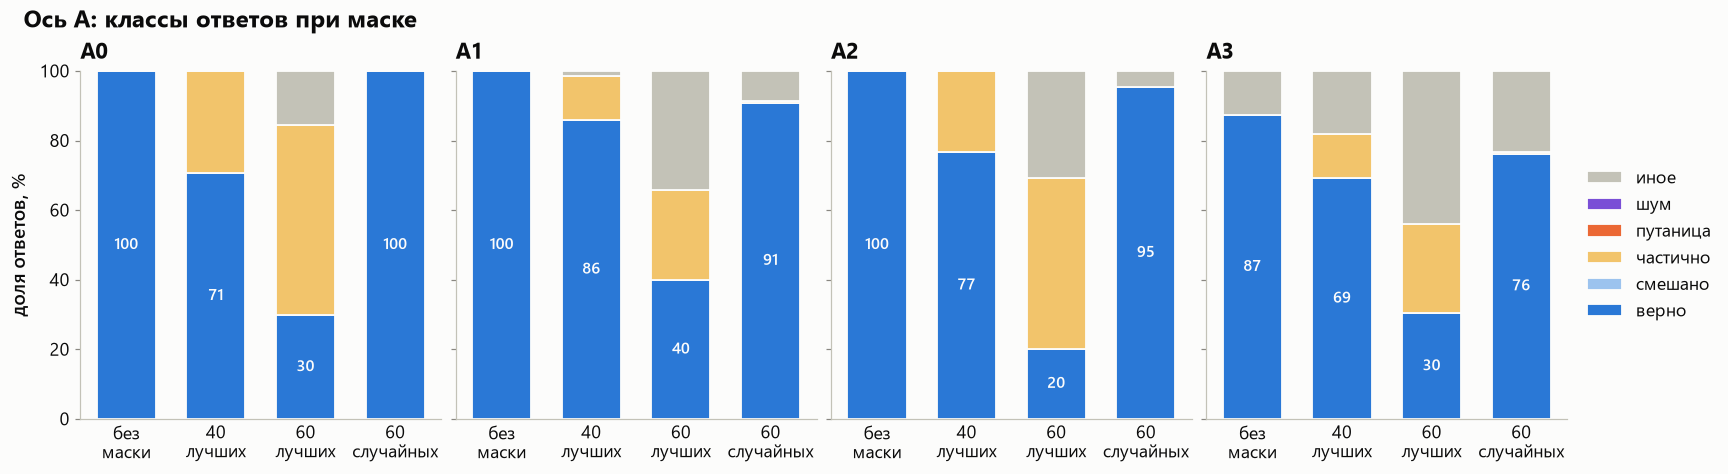

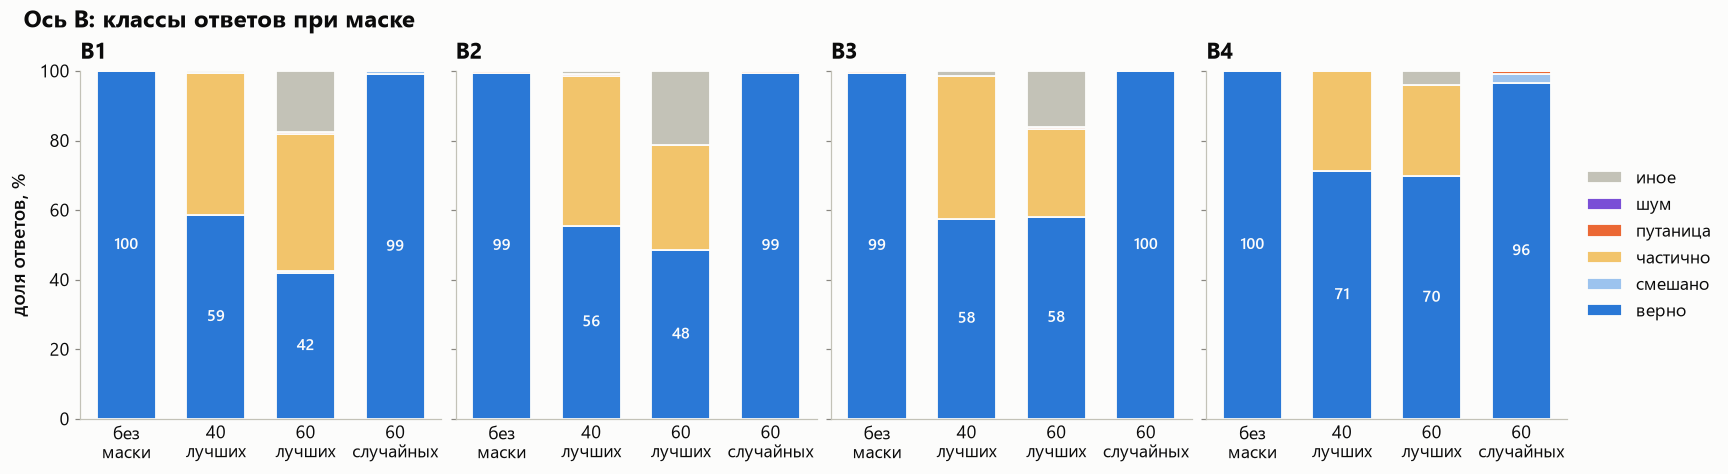

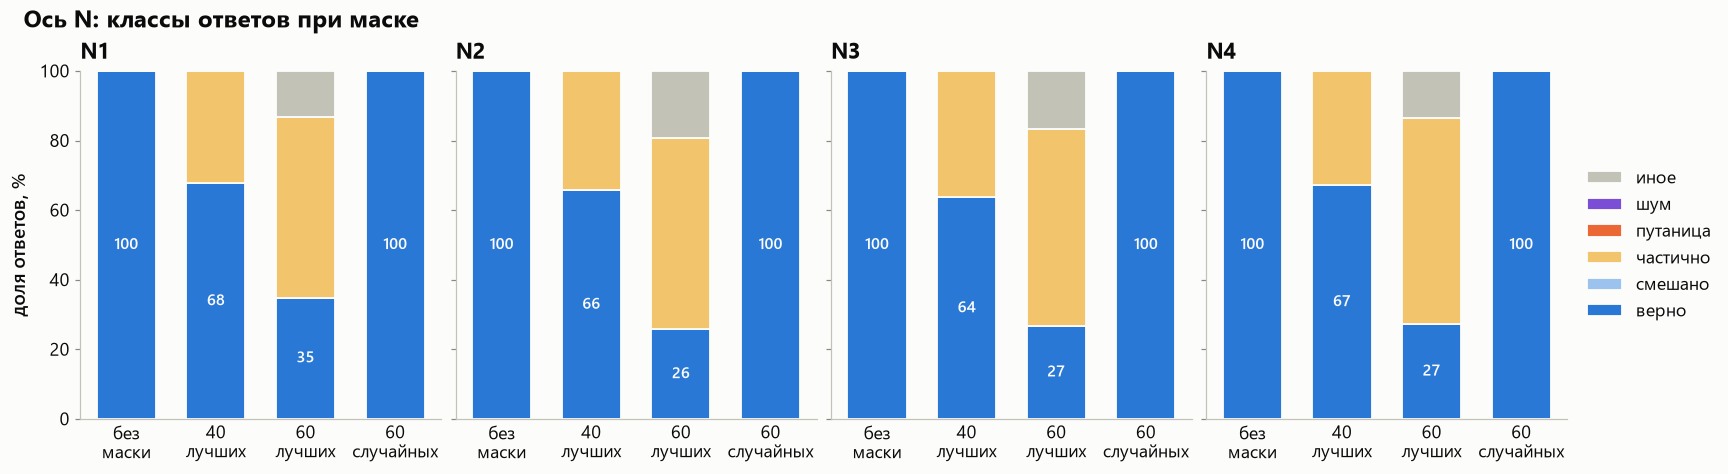

In [10]:
for axis in AXES:
    levels = LEVELS[axis]
    fig, axes = plt.subplots(1, len(levels), figsize=style.size(3.4 * len(levels) + 2, 4.2), sharey=True)
    for ax, level in zip(axes, levels):
        part = hard[(hard["axis"] == axis) & (hard["level"] == level)]
        class_bars(part, "run", RUNS, labels=[RUN_LABELS[r].replace(" ", "\n") for r in RUNS], ax=ax, legend=ax is axes[-1], title=level)
        if ax is not axes[0]:
            ax.set_ylabel("")
    fig.suptitle(f"Ось {axis}: классы ответов при маске", x=0.01, ha="left", fontweight="bold")
    show(axes, f"hard_mask_classes_{axis}")

## 3. Куда смотрят лучшие головы

Прогон без маски сохранил внимание. Для 20 лучших голов детекции (`copy_count`) по каждому уровню:

| Метрика | Что это |
|---|---|
| `needle_sentence_mass` | доля внимания на предложении-игле, среднее по шагам ответа |
| `competing_mass` | доля внимания на всех конкурирующих вставках вместе (близнецы, шум) |
| `competing_max_mass` | на самой «притягательной» из них |
| `copy_count` | копирование ответа из иглы — retrieval score статьи |
| `copy_competing` | копирование из конкурирующих вставок |

`доля на игле = игла / (игла + вставки)`: 1 — головы смотрят только на иглу. Иглы и вставки разной длины, поэтому это доля массы, а не плотности внимания на токен.

In [11]:
ATT = ["copy_count", "needle_sentence_mass", "competing_mass", "competing_max_mass", "copy_competing", "needle_attention_mass"]

def load_heads(axis):
    """Метрики голов прогона без маски: таблица примеров и {метрика: [пример, слой, голова]}; отсутствующая метрика — NaN."""
    out = data.path(f"{RUNS_DIR}/{axis}/none")
    samples = hard[(hard["axis"] == axis) & (hard["run"] == "none")]
    keep, arrays = [], {m: [] for m in ATT}
    for i, sample_id in zip(samples.index, samples["id"]):
        p = os.path.join(out, "heads", f"{sample_id}.npz")
        if not os.path.exists(p):
            continue
        with np.load(p) as d:
            for m in ATT:
                arrays[m].append(d[m] if m in d.files else np.full((len(LAYERS), N_HEADS), np.nan, dtype=np.float32))
        keep.append(i)
    return samples.loc[keep].reset_index(drop=True), {m: np.stack(v) for m, v in arrays.items()}

heads_by_axis = {axis: load_heads(axis) for axis in AXES}
detect_score = data.head_score_file(RANKING, LAYERS, N_HEADS)
chosen = np.zeros_like(detect_score, dtype=bool)
chosen.flat[np.argsort(-detect_score.ravel(), kind="stable")[:TOP]] = True

rows = []
for axis, (samples, arrays) in heads_by_axis.items():
    for level in LEVELS[axis]:
        idx = (samples["level"] == level).to_numpy()
        row = {"axis": axis, "level": level, "примеров": int(idx.sum())}
        for m in ATT:
            row[m] = float(np.nanmean(arrays[m][idx][:, chosen]))
        row["needle_sentence_mass, все головы"] = float(np.nanmean(arrays["needle_sentence_mass"][idx]))
        rows.append(row)
attention = pd.DataFrame(rows)
attention["доля на игле"] = attention["needle_sentence_mass"] / (attention["needle_sentence_mass"] + attention["competing_mass"].fillna(0))
print({axis: f"{len(s)} примеров с метриками голов" for axis, (s, _) in heads_by_axis.items()})
attention.set_index(["axis", "level"]).round(3)

{'A': '792 примеров с метриками голов', 'B': '788 примеров с метриками голов', 'N': '792 примеров с метриками голов'}


примеров  copy_count  needle_sentence_mass  competing_mass  \
axis level                                                               
A    A0          198       0.679                 0.405           0.000   
     A1          198       0.621                 0.334           0.000   
     A2          198       0.678                 0.366           0.000   
     A3          198       0.533                 0.254           0.000   
B    B1          194       0.648                 0.373           0.069   
     B2          198       0.623                 0.345           0.125   
     B3          198       0.609                 0.330           0.144   
     B4          198       0.639                 0.357           0.082   
N    N1          198       0.683                 0.404           0.002   
     N2          198       0.685                 0.406           0.005   
     N3          198       0.689                 0.413           0.012   
     N4          198       0.687                 0.406           0.009   

            competing_max_mass  copy_competing  needle_attention_mass  \
axis level                                                              
A    A0                  0.000           0.000                  0.544   
     A1                  0.000           0.000                  0.506   
     A2                  0.000           0.000                  0.533   
     A3                  0.000           0.000                  0.429   
B    B1                  0.069           0.054                  0.496   
     B2                  0.085           0.074                  0.462   
     B3                  0.094           0.080                  0.442   
     B4                  0.082           0.064                  0.485   
N    N1                  0.002           0.000                  0.544   
     N2                  0.005           0.000                  0.545   
     N3                  0.008           0.000                  0.550   
     N4                  0.009           0.000                  0.545   

            needle_sentence_mass, все головы  доля на игле  
axis level                                                  
A    A0                                0.056         1.000  
     A1                                0.054         1.000  
     A2                                0.052         1.000  
     A3                                0.043         1.000  
B    B1                                0.054         0.844  
     B2                                0.050         0.734  
     B3                                0.046         0.696  
     B4                                0.052         0.813  
N    N1                                0.056         0.996  
     N2                                0.056         0.989  
     N3                                0.057         0.971  
     N4                                0.057         0.977

### 3.1. Игла против вставок по уровням

Слева — масса внимания 20 лучших голов на игле и на вставках; справа — копирование из иглы и из вставок. На оси A вставок нет, там видно только, как меняется внимание на иглу при перефразе вопроса.

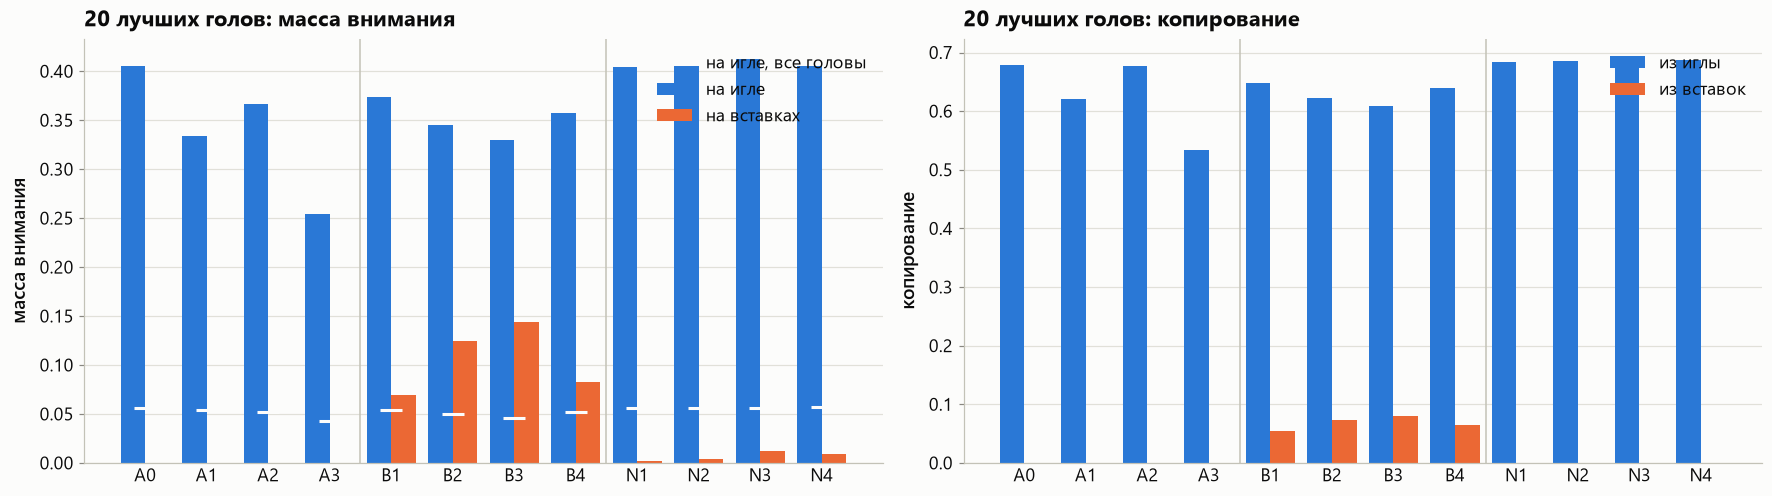

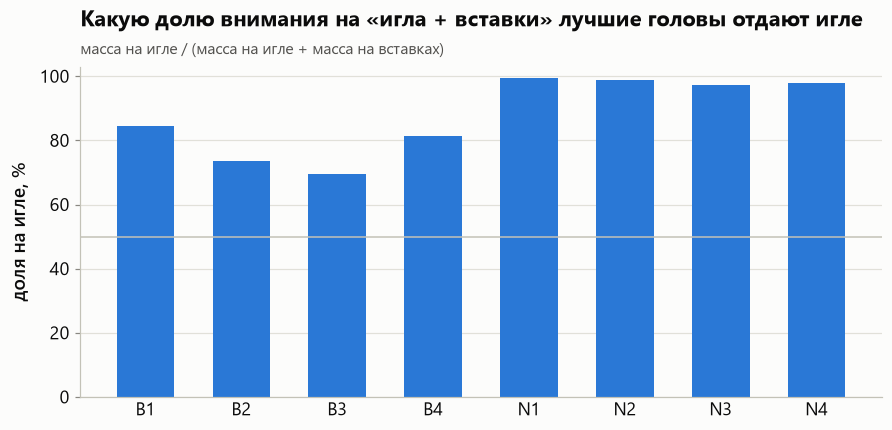

In [12]:
fig, axes = plt.subplots(1, 2, figsize=style.size(16, 4.4))
levels = [l for a in AXES for l in LEVELS[a]]
part = attention.set_index("level").reindex(levels)
xs = np.arange(len(levels))
pairs = [(("needle_sentence_mass", "на игле"), ("competing_mass", "на вставках")), (("copy_count", "из иглы"), ("copy_competing", "из вставок"))]
for ax, ((m1, l1), (m2, l2)), ylabel in zip(axes, pairs, ("масса внимания", "копирование")):
    ax.bar(xs - 0.2, part[m1], width=0.4, color=T.colors["top"], label=l1)
    ax.bar(xs + 0.2, part[m2].fillna(0), width=0.4, color=T.colors["random"], label=l2)
    if m1 == "needle_sentence_mass":
        ax.plot(xs, part["needle_sentence_mass, все головы"], "_", color=T.ink, markersize=14, mew=2, label="на игле, все головы")
    for x in np.cumsum([len(LEVELS[a]) for a in AXES])[:-1] - 0.5:
        ax.axvline(x, color=T.axis, linewidth=1)
    ax.set_xticks(xs, levels)
    ax.tick_params(axis="x", length=0)
    ax.set_ylabel(ylabel)
    ax.legend(loc="upper right")
    plots.titles(ax, f"20 лучших голов: {ylabel}")
show(axes, "hard_attention_levels")

ax = plt.subplots(figsize=style.size(8, 3.8))[1]
rest = [l for l in levels if not l.startswith("A")]
ax.bar(range(len(rest)), part.loc[rest, "доля на игле"] * 100, width=0.6, color=T.colors["top"])
ax.axhline(50, color=T.axis, linewidth=1)
ax.set_xticks(range(len(rest)), rest)
ax.tick_params(axis="x", length=0)
ax.set_ylim(0, 103)
plots.round_axis(ax, "y", 0, 100, 20)
ax.set_ylabel("доля на игле, %")
plots.titles(ax, "Какую долю внимания на «игла + вставки» лучшие головы отдают игле", "масса на игле / (масса на игле + масса на вставках)")
show(ax, "hard_attention_share")

### 3.2. Верные ответы против путаницы

Главная проверка H2: если лучшие головы выбирают нужную запись, то при верном ответе их внимание на игле выше, а на вставках ниже, чем при путанице или шуме. Сравниваются ответы одного уровня; уровни, где каких-то классов меньше 5 примеров, пропускаются.

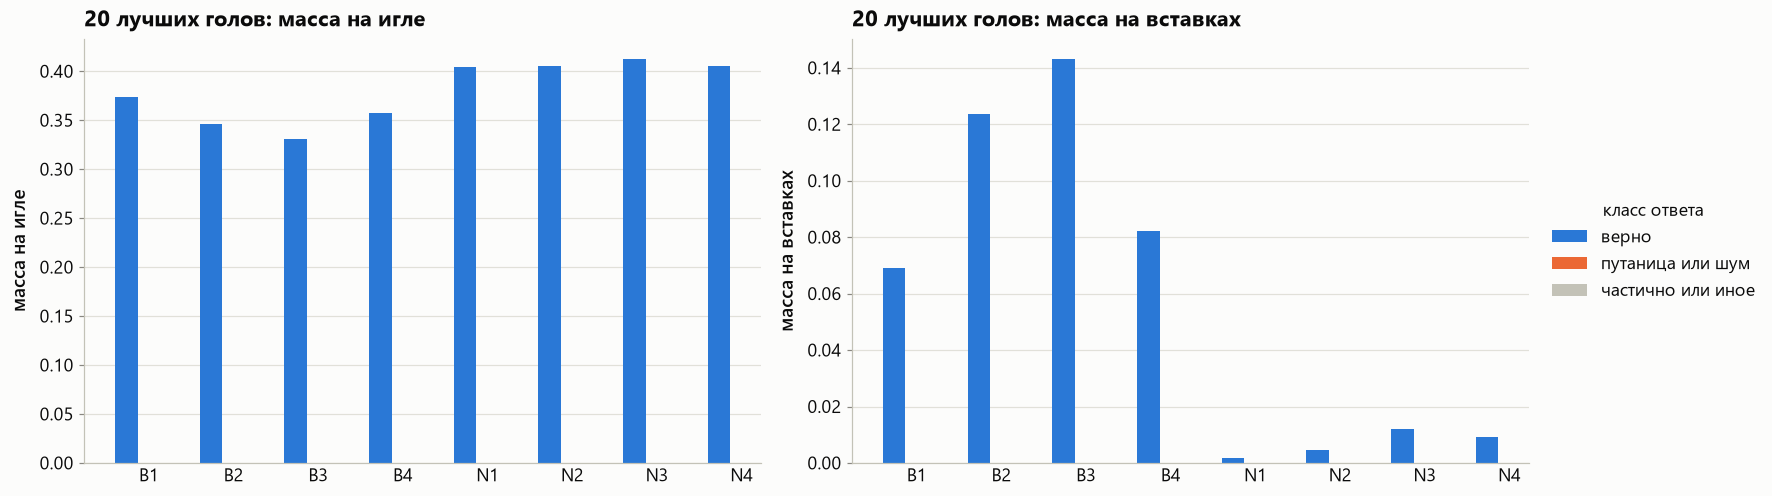

,,примеров,needle_sentence_mass,competing_mass,copy_count,copy_competing
level,группа,,,,,
B1,верно,194,0.373,0.069,0.648,0.054
B2,верно,197,0.347,0.124,0.626,0.071
B3,верно,197,0.330,0.143,0.612,0.078
B4,верно,198,0.357,0.082,0.639,0.064
N1,верно,198,0.404,0.002,0.683,0.000
N2,верно,198,0.406,0.005,0.685,0.000
N3,верно,198,0.413,0.012,0.689,0.000
N4,верно,198,0.406,0.009,0.687,0.000


In [13]:
GROUPS = {"верно": ["correct"], "путаница или шум": ["confusion", "noise", "mixed"], "частично или иное": ["partial", "other"]}
GROUP_COLORS = [CLASS_COLORS["correct"], CLASS_COLORS["confusion"], CLASS_COLORS["other"]]
rows = []
for axis in ("B", "N"):
    samples, arrays = heads_by_axis[axis]
    for level in LEVELS[axis]:
        for group, classes in GROUPS.items():
            idx = ((samples["level"] == level) & samples["answer_class"].isin(classes)).to_numpy()
            if idx.sum() < 5:
                continue
            rows.append({"level": level, "группа": group, "примеров": int(idx.sum()),
                         **{m: float(np.nanmean(arrays[m][idx][:, chosen])) for m in ("needle_sentence_mass", "competing_mass", "copy_count", "copy_competing")}})
by_class = pd.DataFrame(rows)

if by_class.empty:
    print("на осях B и N нет уровней, где ответов каждого вида хотя бы 5")
else:
    levels = [l for l in LEVELS["B"] + LEVELS["N"] if l in set(by_class["level"])]
    fig, axes = plt.subplots(1, 2, figsize=style.size(16, 4.4))
    for ax, metric, label in zip(axes, ("needle_sentence_mass", "competing_mass"), ("масса на игле", "масса на вставках")):
        width = 0.8 / len(GROUPS)
        for i, (group, color) in enumerate(zip(GROUPS, GROUP_COLORS)):
            part = by_class[by_class["группа"] == group].set_index("level").reindex(levels)
            ax.bar(np.arange(len(levels)) + (i - 1) * width, part[metric], width=width, color=color, label=group)
        ax.set_xticks(range(len(levels)), levels)
        ax.tick_params(axis="x", length=0)
        ax.set_ylabel(label)
        plots.titles(ax, f"20 лучших голов: {label}")
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="класс ответа")
    show(axes, "hard_attention_by_class")
by_class.set_index(["level", "группа"]).round(3)

## 4. Остаются ли лучшие головы лучшими

На каждом уровне рейтинг голов строится заново — по среднему скору на примерах с классом «верно» (README: ROUGE для отбора не годится) — и сравнивается с рейтингом простой задачи:

- `copy_count` уровня против `copy_count` детекции (наш рейтинг, по нему шла маска);
- `needle_attention_mass` уровня против рейтинга по массе из `c0` (`MASS_RANKING`).

Показаны пересечение 20 лучших (из 20) и корреляция Спирмена по всем головам. Пунктир — ожидаемое пересечение двух случайных рейтингов (20 · 20 / 1152 ≈ 0.35). Падение на A2–A3 при сохранении на B — довод за H3.

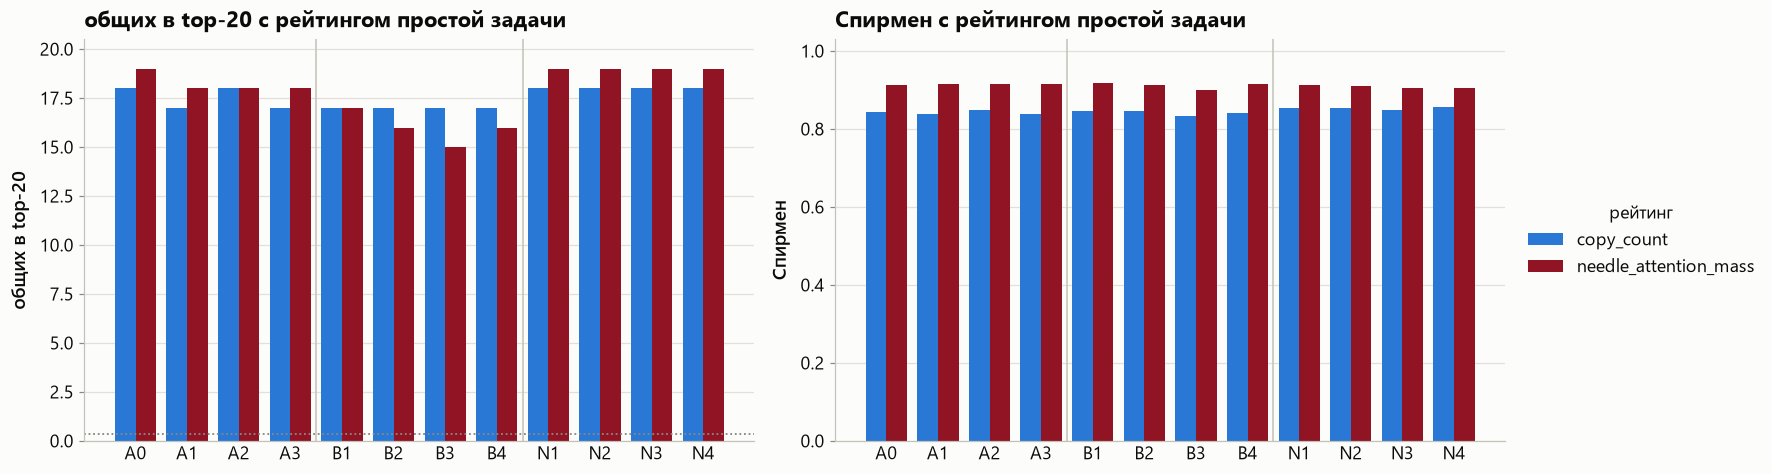

верных примеров  общих в top-20  Спирмен
axis level метрика                                                        
A    A0    copy_count                         198              18    0.843
           needle_attention_mass              198              19    0.914
     A1    copy_count                         198              17    0.838
           needle_attention_mass              198              18    0.916
     A2    copy_count                         198              18    0.849
           needle_attention_mass              198              18    0.916
     A3    copy_count                         173              17    0.839
           needle_attention_mass              173              18    0.916
B    B1    copy_count                         194              17    0.846
           needle_attention_mass              194              17    0.918
     B2    copy_count                         197              17    0.847
           needle_attention_mass              197              16    0.912
     B3    copy_count                         197              17    0.833
           needle_attention_mass              197              15    0.901
     B4    copy_count                         198              17    0.842
           needle_attention_mass              198              16    0.915
N    N1    copy_count                         198              18    0.853
           needle_attention_mass              198              19    0.913
     N2    copy_count                         198              18    0.855
           needle_attention_mass              198              19    0.910
     N3    copy_count                         198              18    0.849
           needle_attention_mass              198              19    0.907
     N4    copy_count                         198              18    0.856
           needle_attention_mass              198              19    0.905

In [14]:
references = {"copy_count": detect_score}
if os.path.exists(data.path(MASS_RANKING)):
    references["needle_attention_mass"] = data.head_score_file(MASS_RANKING, LAYERS, N_HEADS)

rows = []
for axis, (samples, arrays) in heads_by_axis.items():
    for level in LEVELS[axis]:
        idx = ((samples["level"] == level) & (samples["answer_class"] == "correct")).to_numpy()
        for metric, ref in references.items():
            if idx.sum() < 5 or np.isnan(arrays[metric][idx]).all():
                continue
            score = np.nanmean(arrays[metric][idx], axis=0)
            rows.append({"axis": axis, "level": level, "метрика": metric, "верных примеров": int(idx.sum()),
                         f"общих в top-{TOP}": data.top_overlap(score, ref, TOP), "Спирмен": data.spearman(score, ref)})
stable = pd.DataFrame(rows)

levels = [l for a in AXES for l in LEVELS[a]]
fig, axes = plt.subplots(1, 2, figsize=style.size(16, 4.2))
for ax, column in zip(axes, (f"общих в top-{TOP}", "Спирмен")):
    width = 0.8 / max(len(references), 1)
    for i, (metric, color) in enumerate(zip(references, (T.colors["top"], style.RAMP[-2]))):
        part = stable[stable["метрика"] == metric].set_index("level").reindex(levels)
        ax.bar(np.arange(len(levels)) + (i - (len(references) - 1) / 2) * width, part[column], width=width, color=color, label=metric)
    for x in np.cumsum([len(LEVELS[a]) for a in AXES])[:-1] - 0.5:
        ax.axvline(x, color=T.axis, linewidth=1)
    if column.startswith("общих"):
        ax.axhline(TOP * TOP / detect_score.size, color=T.ink_muted, linestyle=(0, (1, 1.5)), linewidth=1.2)
        ax.set_ylim(0, TOP + 0.5)
    else:
        ax.set_ylim(0, 1.03)
    ax.set_xticks(range(len(levels)), levels)
    ax.tick_params(axis="x", length=0)
    ax.set_ylabel(column)
    plots.titles(ax, column + " с рейтингом простой задачи")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="рейтинг")
show(axes, "hard_ranking_stability")
stable.set_index(["axis", "level", "метрика"]).round(3)

## 5. Примеры ответов

По два самых коротких ответа каждого класса без маски на уровнях с дистракторами: что именно модель списала с близнеца или шума.

In [15]:
pd.set_option("display.max_colwidth", 300)
wrong = none[none["answer_class"].isin(["confusion", "noise", "mixed", "partial", "other"]) & (none["axis"] != "A")]
examples = wrong.sort_values("n_tokens").groupby(["level", "answer_class"]).head(2)
examples.assign(класс=examples["answer_class"].map(CLASS_LABELS)).sort_values(["level", "класс"]).set_index(["level", "класс"])[
    ["family", "context_length", "depth_percent", "rouge1_recall", "reference", "response"]].round(0)

,,family,context_length,depth_percent,rouge1_recall,reference,response
level,класс,,,,,,
B2,путаница,oslo,28474,22,46.0,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a wall of yellow brick and a gate carved with a blue anchor.
B3,путаница,cairo,28474,22,54.0,cooked with smoked lemon peel and served in a bowl of black clay,The famous soup of the Zahira Cafe in Cairo is cooked with dried fig leaves and served in a cup of blue glass.


## 6. Ограничения

- **Три семейства.** Хватает, чтобы отличить эффект уровня от свойства одной фразы (раздел 1.1, по семействам), но не для интервалов по семействам: бутстреп идёт по примерам, а примеры одного семейства похожи, поэтому интервалы скорее узкие, чем широкие.
- **198 примеров на уровень.** Надёжно видны различия от ~10 п. п.; разница соседних уровней меньше этого — в пределах шума.
- **Класс ответа по фактам строгий:** «ring the bell» вместо «ring the brass bell» — это «частично». Часть «частичных» ответов по смыслу верны.
- **Одна точка маски для контроля:** случайные 60 голов с одним seed.
- **Доля на игле — по массе, а не по плотности:** игла и вставки разной длины; селективность по плотности на токен (`S_first`, `S_mean` из плана) здесь не считается.
- **Ранжирование на уровне** (раздел 4) идёт по верным ответам; на трудных уровнях их меньше, и рейтинг шумнее. Потолок шума (split-half) не вычислен.